# Optimal to operate: the same ESC parameter sets on every fixed plant (8 plants, 40,000 sets)

**Question.** Which ESC parameter sets work well on *all* fixed plants, and how fast do they get there?

**Data.** Eight files `OTO-paired-<r_ideal_0>_<lambda>-40k.csv`, generated by `OTO_ESC_paired_Plant_fix.py` with the
Python simulator (`Tools/esc_sim.py`). Row *i* is the same ESC parameter set in every file.

How this differs from `OTO-Plant_fix.ipynb`:

| | `OTO-Plant_fix` | this notebook |
|---|---|---|
| ESC sets | 100,000 per plant, different for every plant | 40,000, the same for every plant |
| Ranges | $k$ 1e-5 to 5, $a$ 0 to 1, $f$ 0 to 10 Hz | $k$ 0.02 to 5, $a$ 0 to 0.6, $f$ 1.5 to 10 Hz (where ESC is useful) |
| Start of a run | 25 % density, deuterium-rich | plasma already running: full density, steady state with $r = 0.5$ |
| Best-possible reference | none (`energy_max` cannot be reached) | `energy_ideal`: the ratio follows $r_\mathrm{ideal}(t)$ exactly |
| Speed measure | $\hat r$ within 5 % of $r_\mathrm{ideal}$ for 5 s | ratio received by the plasma within a fixed distance of $r_\mathrm{ideal}$ |

The group limits and tolerances used below are proposals. They are set in one place (Section 3 and Section 5).

## 1. Setup

In [1]:
# Shared tools (plot style, model constants, averaged-ESC formulas) live in Tools/ at the repository root
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import esc_tools as esc

esc.apply_style()   # one plot style for every notebook in this repository

In [2]:
files = {
    '0.5 up 0.001':       'OTO-paired-0.5_0.001-40k.csv',
    '0.5 down 0.001':     'OTO-paired-0.5_-0.001-40k.csv',
    '0.55 up 0.002':      'OTO-paired-0.55_0.002-40k.csv',
    '0.45 down 0.002':    'OTO-paired-0.45_-0.002-40k.csv',
    '0.525':              'OTO-paired-0.525-40k.csv',
    '0.475':              'OTO-paired-0.475-40k.csv',
    '0.5375 down 0.0015': 'OTO-paired-0.5375_-0.0015-40k.csv',
    '0.4625 up 0.0015':   'OTO-paired-0.4625_0.0015-40k.csv',
}
pairs = [('0.5 up 0.001', '0.5 down 0.001'), ('0.55 up 0.002', '0.45 down 0.002'), ('0.525', '0.475'),
         ('0.5375 down 0.0015', '0.4625 up 0.0015')]
dfs = {name: pd.read_csv(file) for name, file in files.items()}

# row i must be the same ESC parameter set in every file
esc_sets = dfs['0.5 up 0.001'][esc.ESC_PARAMS]
assert all((d[esc.ESC_PARAMS].to_numpy() == esc_sets.to_numpy()).all() for d in dfs.values())
print(f'{len(esc_sets):,} ESC parameter sets on {len(dfs)} plants')
dfs['0.5 up 0.001'].head()

40,000 ESC parameter sets on 8 plants


,optimizer_gain,dither_amplitude,dither_frequency,r_ideal_0,lambda_r_ideal,energy_ESC,energy_const,energy_ideal,energy_max,choose_ESC,tracking_error,tracking_error_late,settling_time_0.01,settling_time_0.02,converged,convergence_time
0,0.040322,0.488834,9.199231,0.5,0.001,3305.419074,3295.131063,3306.25,3306.25,1,0.007065,0.008247,0.97,0.97,1,0.0
1,0.034271,0.548026,6.875054,0.5,0.001,3304.871109,3295.131063,3306.25,3306.25,1,0.008682,0.010217,NaN,1.01,1,0.0
2,3.954339,0.167099,6.148493,0.5,0.001,3306.191785,3295.131063,3306.25,3306.25,1,0.001267,0.000951,0.97,0.97,1,0.0
3,4.250630,0.578933,2.839711,0.5,0.001,3262.257289,3295.131063,3306.25,3306.25,0,0.149733,0.151800,NaN,NaN,0,NaN
4,1.659795,0.574300,5.625693,0.5,0.001,3305.674748,3295.131063,3306.25,3306.25,1,0.001651,0.001417,2.65,1.06,1,0.0


## 2. Data overview

`margin` is what ESC can win at most on a plant: `energy_ideal` minus `energy_const`.

In [3]:
rows = []
for name, d in dfs.items():
    r0, lam = d['r_ideal_0'].iloc[0], d['lambda_r_ideal'].iloc[0]
    rows.append({'plant': name, 'r_ideal at 0 s': r0, 'r_ideal at 100 s': r0 * np.exp(lam * esc.T_END),
                 'energy, r = 0.5': d['energy_const'].iloc[0], 'energy, ideal': d['energy_ideal'].iloc[0],
                 'margin': d['energy_ideal'].iloc[0] - d['energy_const'].iloc[0],
                 'best ESC run minus ideal': d['energy_ESC'].max() - d['energy_ideal'].iloc[0],
                 'ESC wins': d['choose_ESC'].mean()})
summary = pd.DataFrame(rows).set_index('plant')
summary.round(3)

,r_ideal at 0 s,r_ideal at 100 s,"energy, r = 0.5","energy, ideal",margin,best ESC run minus ideal,ESC wins
plant,,,,,,,
0.5 up 0.001,0.500,0.553,3295.131,3306.250,11.119,-0.001,0.951
0.5 down 0.001,0.500,0.452,3296.650,3306.250,9.600,-0.001,0.949
0.55 up 0.002,0.550,0.672,3140.626,3305.814,165.187,-0.061,1.000
0.45 down 0.002,0.450,0.368,3190.750,3305.814,115.064,-0.049,1.000
0.525,0.525,0.525,3297.984,3306.141,8.157,-0.006,0.941
0.475,0.475,0.475,3297.984,3306.141,8.157,0.013,0.935
0.5375 down 0.0015,0.538,0.463,3300.056,3306.005,5.950,0.040,0.930
0.4625 up 0.0015,0.462,0.537,3300.051,3306.005,5.954,0.017,0.923


## 3. Energy score and energy groups

For every run, the energy score is the share of the margin that ESC wins:

$$\eta = \frac{E_\mathrm{ESC} - E_{r=0.5}}{E_\mathrm{ideal} - E_{r=0.5}}$$

$\eta = 1$: as good as following $r_\mathrm{ideal}$ exactly. $\eta = 0$: no better than $r = 0.5$. $\eta < 0$: worse.

| group | rule |
|---|---|
| A near-optimal | $\eta \ge 0.9$ |
| B useful | $0.5 \le \eta < 0.9$ |
| C small gain | $0.1 \le \eta < 0.5$ |
| N neutral | $-0.1 < \eta < 0.1$ |
| L loses | $\eta \le -0.1$, loss up to 1 % of the energy |
| F fails | loss of more than 1 % of the energy |

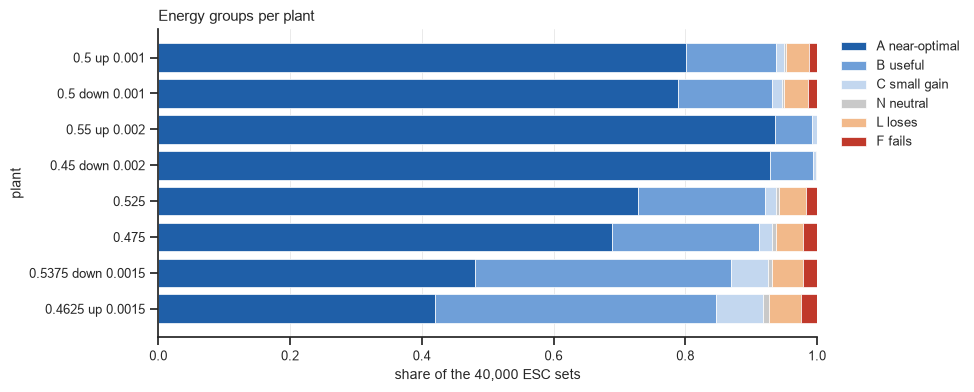

energy_group,A near-optimal,B useful,C small gain,N neutral,L loses,F fails
0.5 up 0.001,80.1,13.6,1.3,0.2,3.5,1.2
0.5 down 0.001,78.9,14.3,1.5,0.3,3.6,1.4
0.55 up 0.002,93.6,5.7,0.7,0.0,0.0,0.0
0.45 down 0.002,92.8,6.5,0.5,0.1,0.0,0.0
0.525,72.8,19.3,1.7,0.4,4.1,1.7
0.475,68.8,22.4,2.0,0.5,4.2,2.1
0.5375 down 0.0015,48.1,38.9,5.6,0.6,4.6,2.2
0.4625 up 0.0015,42.0,42.8,7.1,0.8,4.9,2.4


In [4]:
ENERGY_GROUPS = ['A near-optimal', 'B useful', 'C small gain', 'N neutral', 'L loses', 'F fails']
GROUP_COLORS = ['#1f5fa8', '#6f9fd8', '#c3d7ef', '#c9c9c9', '#f2b98a', '#c0392b']
FAIL_FRACTION = 0.01     # a loss of more than 1 % of the fixed-ratio energy counts as a failure


def add_energy_score(d):
    """Add the energy score eta and the energy group to the runs of one plant."""
    fixed, ideal = d['energy_const'].iloc[0], d['energy_ideal'].iloc[0]
    eta = (d['energy_ESC'] - fixed) / (ideal - fixed)
    loss = fixed - d['energy_ESC']
    group = np.select([eta >= 0.9, eta >= 0.5, eta >= 0.1, eta > -0.1, loss <= FAIL_FRACTION * fixed],
                      ENERGY_GROUPS[:5], default=ENERGY_GROUPS[5])
    return d.assign(eta=eta, energy_group=pd.Categorical(group, ENERGY_GROUPS))


dfs = {name: add_energy_score(d) for name, d in dfs.items()}
energy_shares = pd.DataFrame({name: d['energy_group'].value_counts(normalize=True).reindex(ENERGY_GROUPS)
                              for name, d in dfs.items()}).T

fig, ax = plt.subplots(figsize=(8.5, 4))
left = np.zeros(len(energy_shares))
for group, color in zip(ENERGY_GROUPS, GROUP_COLORS):
    ax.barh(np.arange(len(energy_shares)), energy_shares[group], left=left, color=color, edgecolor='white',
            linewidth=0.5, label=group)
    left += energy_shares[group].to_numpy()
ax.set_yticks(np.arange(len(energy_shares)))
ax.set_yticklabels(energy_shares.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('share of the 40,000 ESC sets')
ax.set_ylabel('plant')
ax.set_title('Energy groups per plant')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.show()
(energy_shares * 100).round(1)

## 4. Speed and tracking

Two measures, both from the ratio the plasma **receives** (after clipping to [0, 1]), averaged over 1 s:

- **Tracking error**: the mean distance to $r_\mathrm{ideal}$. A number, not yes/no, with the same meaning on every plant.
- **Settling time**: the time after which the distance stays below a tolerance until the end of the run.
  Two tolerances are stored, 0.01 and 0.02. In steady state a ratio error $\Delta$ costs about $4\Delta^2$ of the
  power, so 0.01 corresponds to 0.04 % and 0.02 to 0.16 %.

The first table compares them with the old measure. The figure shows how many sets have settled as a function of time.

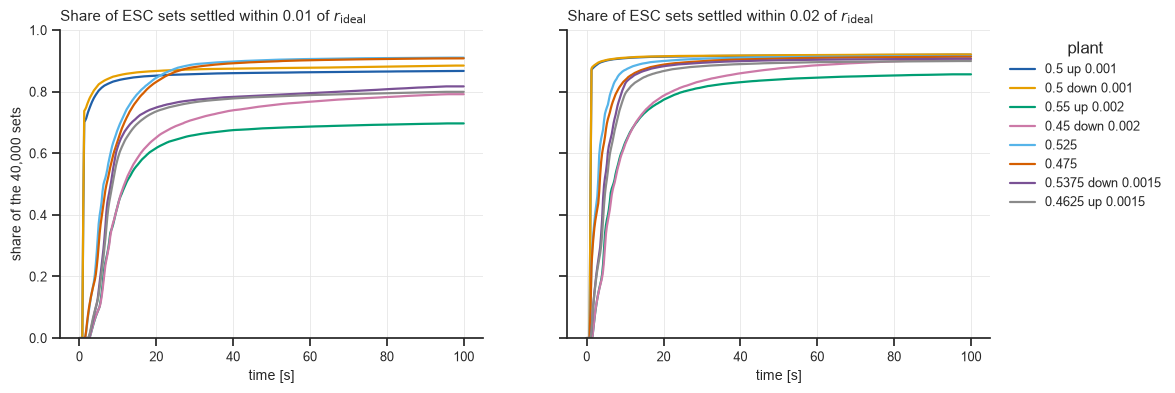

,old: converged,old: convergence time 0,settled within 0.01,settled within 0.02,median settling time (0.02) [s],"median tracking error, 50-100 s"
plant,,,,,,
0.5 up 0.001,0.932,0.894,0.867,0.920,1.00,0.002
0.5 down 0.001,0.932,0.897,0.885,0.921,1.00,0.001
0.55 up 0.002,0.886,0.000,0.697,0.856,5.89,0.004
0.45 down 0.002,0.853,0.000,0.792,0.905,6.37,0.003
0.525,0.915,0.660,0.911,0.915,2.74,0.001
0.475,0.912,0.000,0.908,0.914,3.15,0.001
0.5375 down 0.0015,0.913,0.000,0.817,0.907,4.27,0.002
0.4625 up 0.0015,0.912,0.000,0.799,0.900,4.62,0.002


In [5]:
rows = []
for name, d in dfs.items():
    rows.append({'plant': name,
                 'old: converged': d['converged'].mean(),
                 'old: convergence time 0': (d['convergence_time'] == 0).mean(),
                 'settled within 0.01': d['settling_time_0.01'].notna().mean(),
                 'settled within 0.02': d['settling_time_0.02'].notna().mean(),
                 'median settling time (0.02) [s]': d['settling_time_0.02'].median(),
                 'median tracking error, 50-100 s': d['tracking_error_late'].median()})
speed = pd.DataFrame(rows).set_index('plant')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
time_axis = np.linspace(0, esc.T_END, 400)
for ax, tolerance in zip(axes, ['0.01', '0.02']):
    for (name, d), color in zip(dfs.items(), esc.CYCLE):
        settled = np.sort(d[f'settling_time_{tolerance}'].dropna().to_numpy())
        ax.plot(time_axis, np.searchsorted(settled, time_axis, side='right') / len(d), color=color, label=name)
    ax.set_xlabel('time [s]')
    ax.set_title(f'Share of ESC sets settled within {tolerance} of $r_\\mathrm{{ideal}}$')
axes[0].set_ylabel('share of the 40,000 sets')
axes[0].set_ylim(0, 1)
axes[1].legend(title='plant', loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.show()
speed.round(3)

**Old and new measure for runs with near-optimal energy.** Among the runs of group A, the share that counts as
converged (old measure, on $\hat r$) and the share that settles within 0.02 (new measure, on the received ratio),
by dither amplitude.

In [6]:
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
rows = {}
for name, d in dfs.items():
    best = d[d['energy_group'] == 'A near-optimal']
    by_amplitude = best.groupby(pd.cut(best['dither_amplitude'], bins), observed=True)
    rows[(name, 'old: converged')] = by_amplitude['converged'].mean()
    rows[(name, 'settled within 0.02')] = by_amplitude['settling_time_0.02'].apply(lambda s: s.notna().mean())
pd.DataFrame(rows).T.round(2)

dither_amplitude                        (0.0, 0.1]  (0.1, 0.2]  (0.2, 0.3]  \
0.5 up 0.001       old: converged             1.00        1.00        1.00   
                   settled within 0.02        0.98        0.99        1.00   
0.5 down 0.001     old: converged             1.00        1.00        1.00   
                   settled within 0.02        0.98        0.99        1.00   
0.55 up 0.002      old: converged             1.00        0.94        0.93   
                   settled within 0.02        0.95        0.90        0.89   
0.45 down 0.002    old: converged             0.99        0.93        0.96   
                   settled within 0.02        0.99        0.93        0.96   
0.525              old: converged             0.98        1.00        1.00   
                   settled within 0.02        0.98        1.00        1.00   
0.475              old: converged             0.98        1.00        1.00   
                   settled within 0.02        0.98        1.00        1.00   
0.5375 down 0.0015 old: converged             0.99        1.00        1.00   
                   settled within 0.02        0.99        1.00        1.00   
0.4625 up 0.0015   old: converged             0.99        1.00        1.00   
                   settled within 0.02        0.99        1.00        1.00   

dither_amplitude                        (0.3, 0.4]  (0.4, 0.5]  (0.5, 0.6]  
0.5 up 0.001       old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00  
0.5 down 0.001     old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00  
0.55 up 0.002      old: converged             0.97        0.97        0.74  
                   settled within 0.02        0.92        0.91        0.91  
0.45 down 0.002    old: converged             0.98        0.97        0.61  
                   settled within 0.02        0.98        0.98        0.99  
0.525              old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00  
0.475              old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00  
0.5375 down 0.0015 old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00  
0.4625 up 0.0015   old: converged             1.00        1.00        1.00  
                   settled within 0.02        1.00        1.00        1.00

## 5. One ESC set on all plants: the worst plant decides

Every ESC set now has eight results. A set is judged by its **worst** plant:

- worst energy score: the lowest $\eta$ over the eight plants;
- worst settling time: the longest settling time over the eight plants (never settled on some plant: no value);
- worst tracking error: the largest late tracking error over the eight plants.

| tier | rule |
|---|---|
| robust A | $\eta \ge 0.9$ on every plant |
| robust B | $\eta \ge 0.5$ on every plant |
| gain on every plant | $\eta > 0$ on every plant |
| loses on some plant | otherwise |

In [7]:
TOLERANCE = '0.02'      # tolerance used for the settling time below
TIERS = ['robust A', 'robust B', 'gain on every plant', 'loses on some plant']

eta = pd.DataFrame({name: d['eta'] for name, d in dfs.items()})
settling = pd.DataFrame({name: d[f'settling_time_{TOLERANCE}'] for name, d in dfs.items()})
tracking = pd.DataFrame({name: d['tracking_error_late'] for name, d in dfs.items()})

sets = esc_sets.copy()
sets['log10_gain'] = np.log10(sets['optimizer_gain'])
sets['worst eta'] = eta.min(axis=1)
sets['worst plant'] = eta.idxmin(axis=1)
sets['mean eta'] = eta.mean(axis=1)
sets['worst settling time'] = settling.max(axis=1).where(settling.notna().all(axis=1))   # NaN: not settled somewhere
sets['worst tracking error'] = tracking.max(axis=1)
sets['tier'] = pd.Categorical(np.select([sets['worst eta'] >= 0.9, sets['worst eta'] >= 0.5, sets['worst eta'] > 0],
                                        TIERS[:3], default=TIERS[3]), TIERS)

tier_table = pd.DataFrame({'sets': sets['tier'].value_counts().reindex(TIERS),
                           'share': sets['tier'].value_counts(normalize=True).reindex(TIERS),
                           'settled on every plant': sets.groupby('tier', observed=False)['worst settling time'].apply(lambda s: s.notna().mean()),
                           'median worst settling time [s]': sets.groupby('tier', observed=False)['worst settling time'].median()})
print('plant that gives the worst energy score (share of sets):')
print(sets['worst plant'].value_counts(normalize=True).round(3).to_string())
tier_table.round(3)

plant that gives the worst energy score (share of sets):
worst plant
0.4625 up 0.0015      0.983
0.5375 down 0.0015    0.014
0.55 up 0.002         0.001
0.475                 0.001
0.525                 0.000
0.45 down 0.002       0.000


,sets,share,settled on every plant,median worst settling time [s]
tier,,,,
robust A,16701,0.418,0.994,4.935
robust B,17107,0.428,0.914,7.880
gain on every plant,3046,0.076,0.405,8.540
loses on some plant,3146,0.079,0.073,9.690


**Where the robust sets are.** Left: share of sets that are robust A in each region of the parameter space.
Right: median of the worst settling time of the robust-A sets in that region (white: no robust-A set that settles
on every plant). Both maps use about 44 × 44 bins (about 20 sets per bin), smoothed over 1.5 bins.

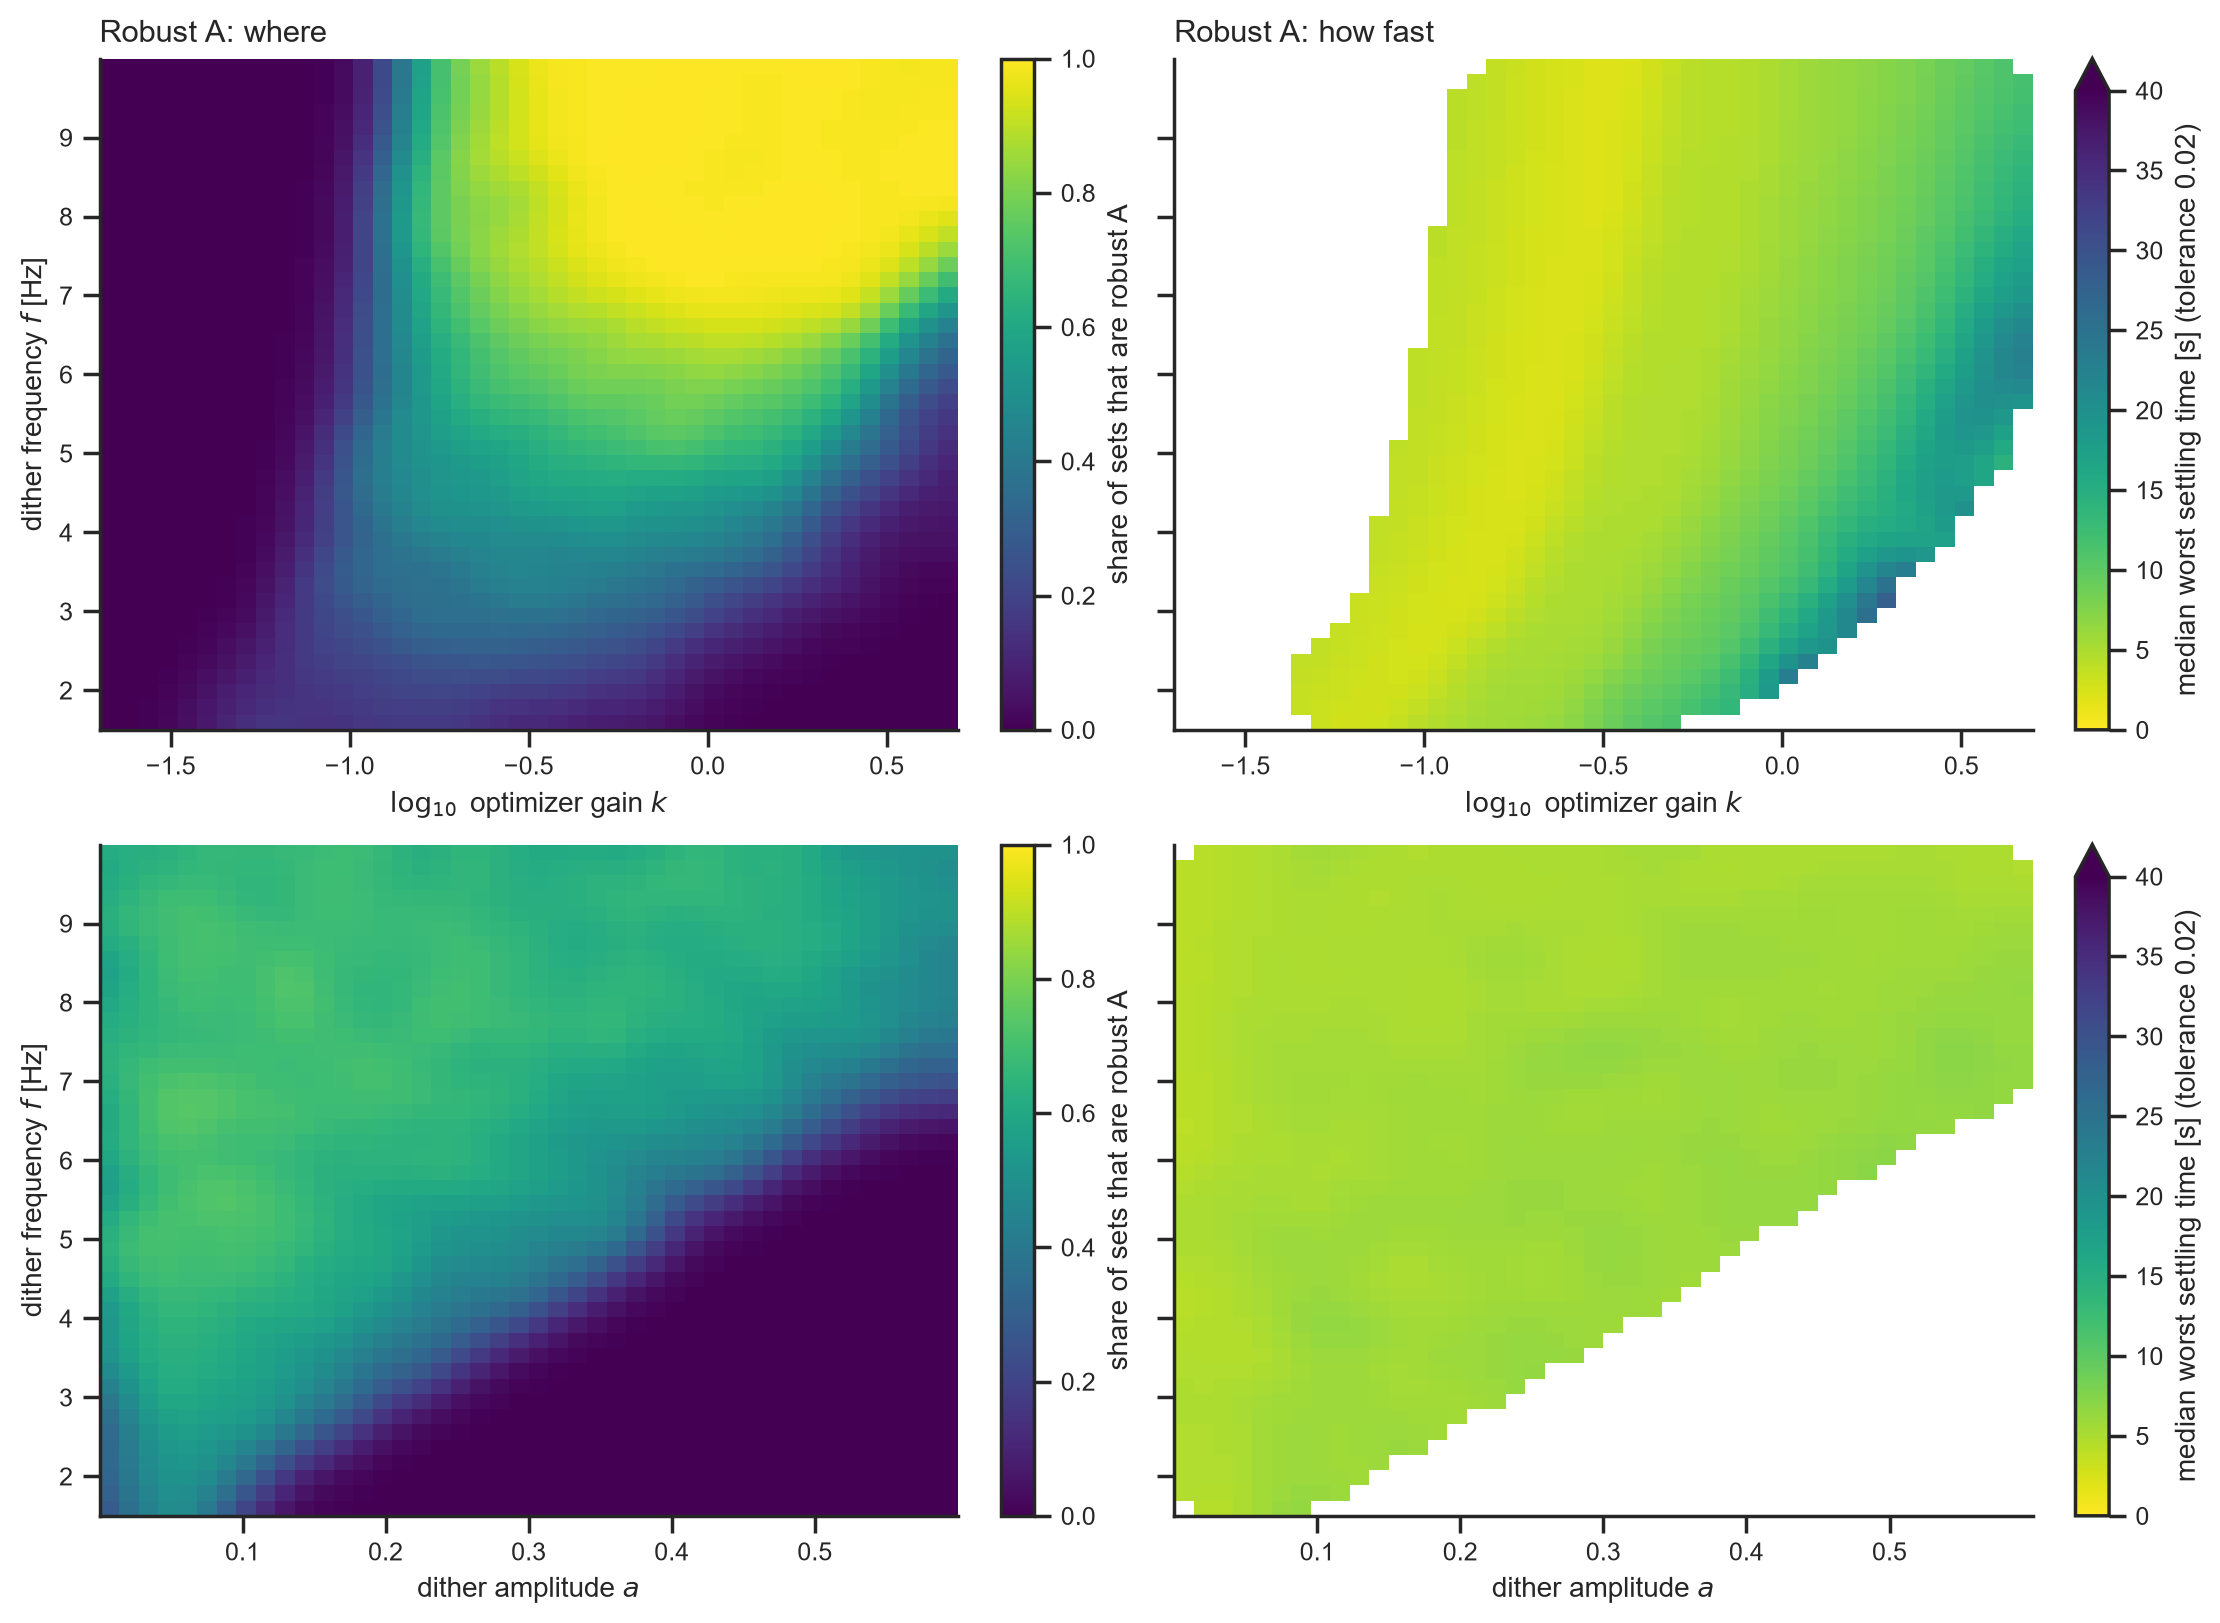

In [8]:
views = [('log10_gain', esc.LABELS['log10_gain']), ('dither_amplitude', esc.LABELS['dither_amplitude'])]
robust = sets['tier'] == 'robust A'
fast = robust & sets['worst settling time'].notna()
N_BINS = esc.bins_for(len(sets))   # bins per axis: about 20 sets per bin before smoothing (esc.binned_map)

# dpi=200: twice the usual resolution, so the maps stay sharp when the notebook shrinks the figure
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True, layout='constrained', dpi=200)
for row, (x, x_label) in enumerate(views):
    x_edges = np.linspace(sets[x].min(), sets[x].max(), N_BINS + 1)
    y_edges = np.linspace(sets['dither_frequency'].min(), sets['dither_frequency'].max(), N_BINS + 1)
    share = esc.binned_map(sets[x], sets['dither_frequency'], robust.astype(float), x_edges, y_edges)
    image = axes[row, 0].pcolormesh(x_edges, y_edges, share.T, cmap='viridis', vmin=0, vmax=1)
    fig.colorbar(image, ax=axes[row, 0], label='share of sets that are robust A')
    time_map = esc.binned_map(sets.loc[fast, x], sets.loc[fast, 'dither_frequency'], sets.loc[fast, 'worst settling time'],
                              x_edges, y_edges, statistic='median')
    image = axes[row, 1].pcolormesh(x_edges, y_edges, time_map.T, cmap='viridis_r', vmin=0, vmax=40)
    fig.colorbar(image, ax=axes[row, 1], label=f'median worst settling time [s] (tolerance {TOLERANCE})', extend='max')
    for ax in axes[row]:
        ax.set_xlabel(x_label)
        ax.grid(False)
    axes[row, 0].set_ylabel(esc.LABELS['dither_frequency'])
axes[0, 0].set_title('Robust A: where')
axes[0, 1].set_title('Robust A: how fast')
plt.show()

**The same four maps, one per figure** (larger, easier to read).

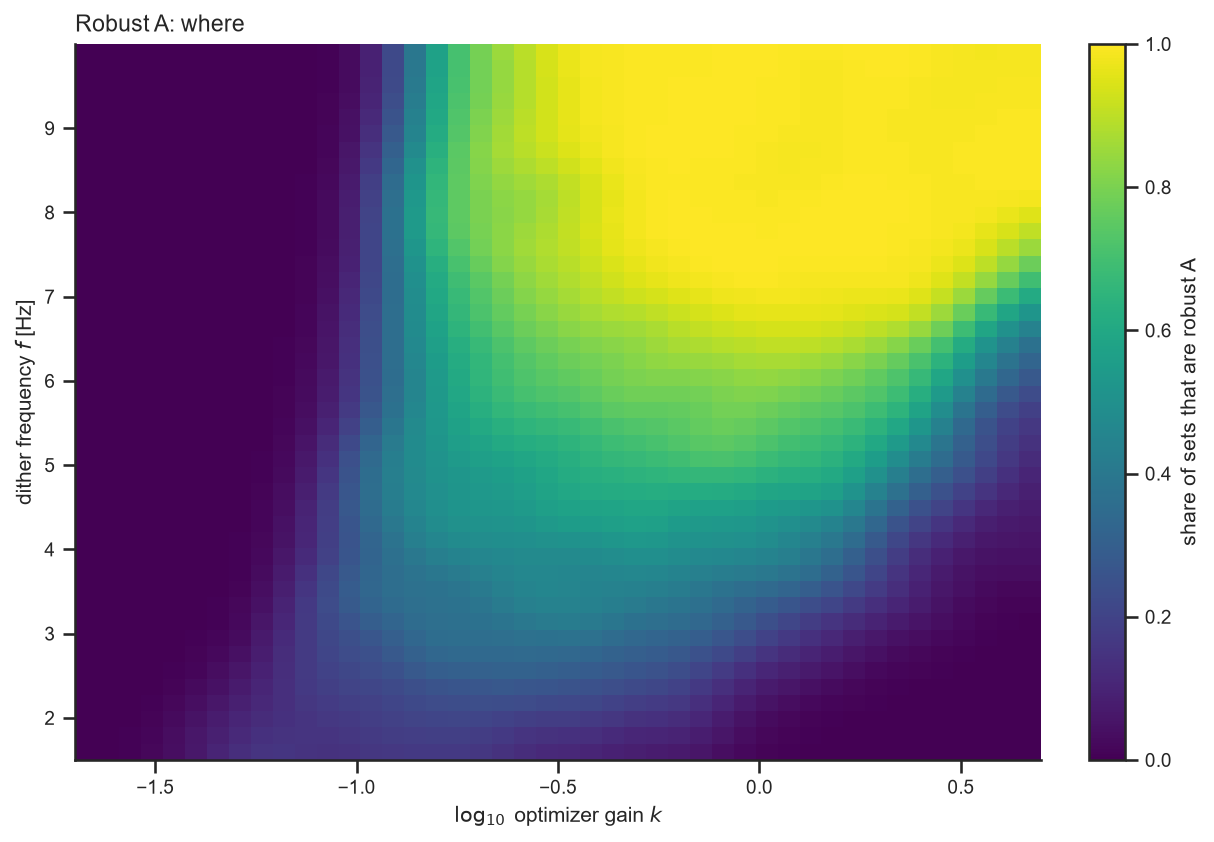

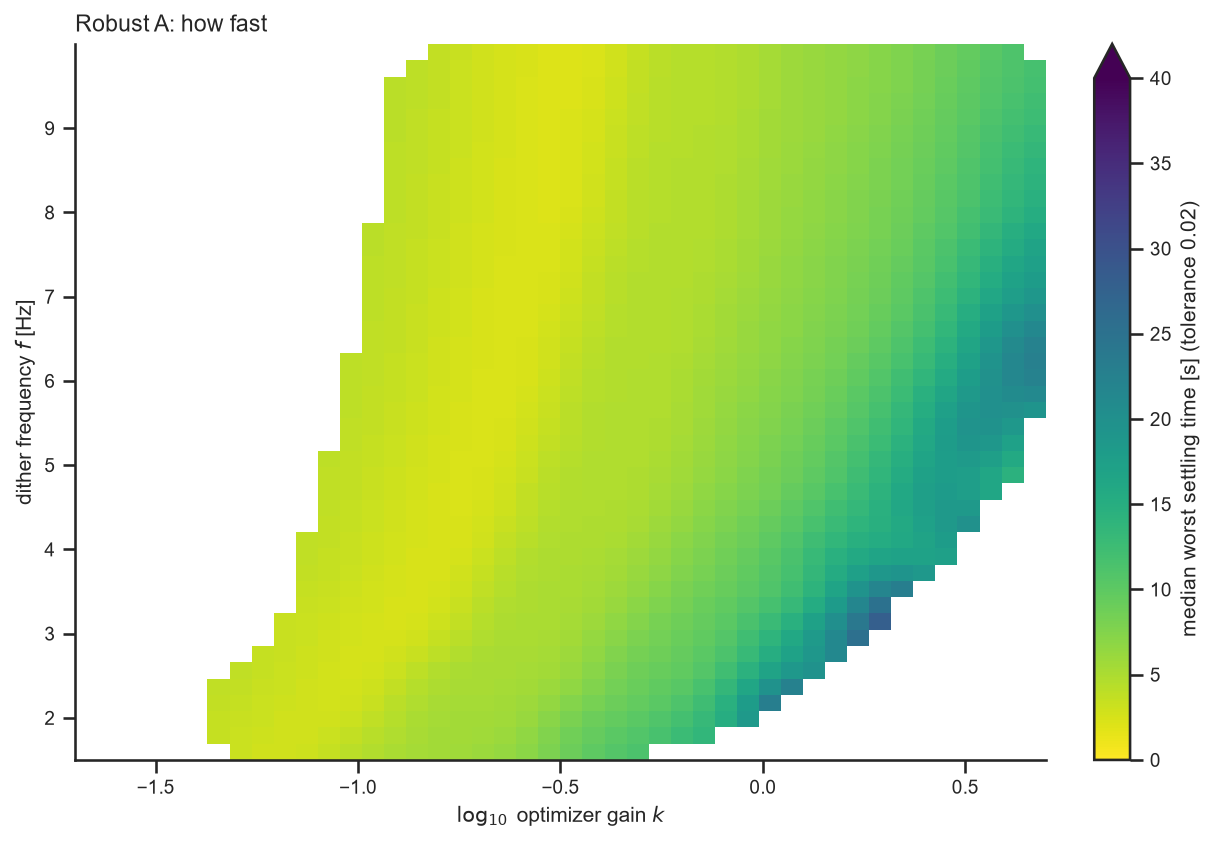

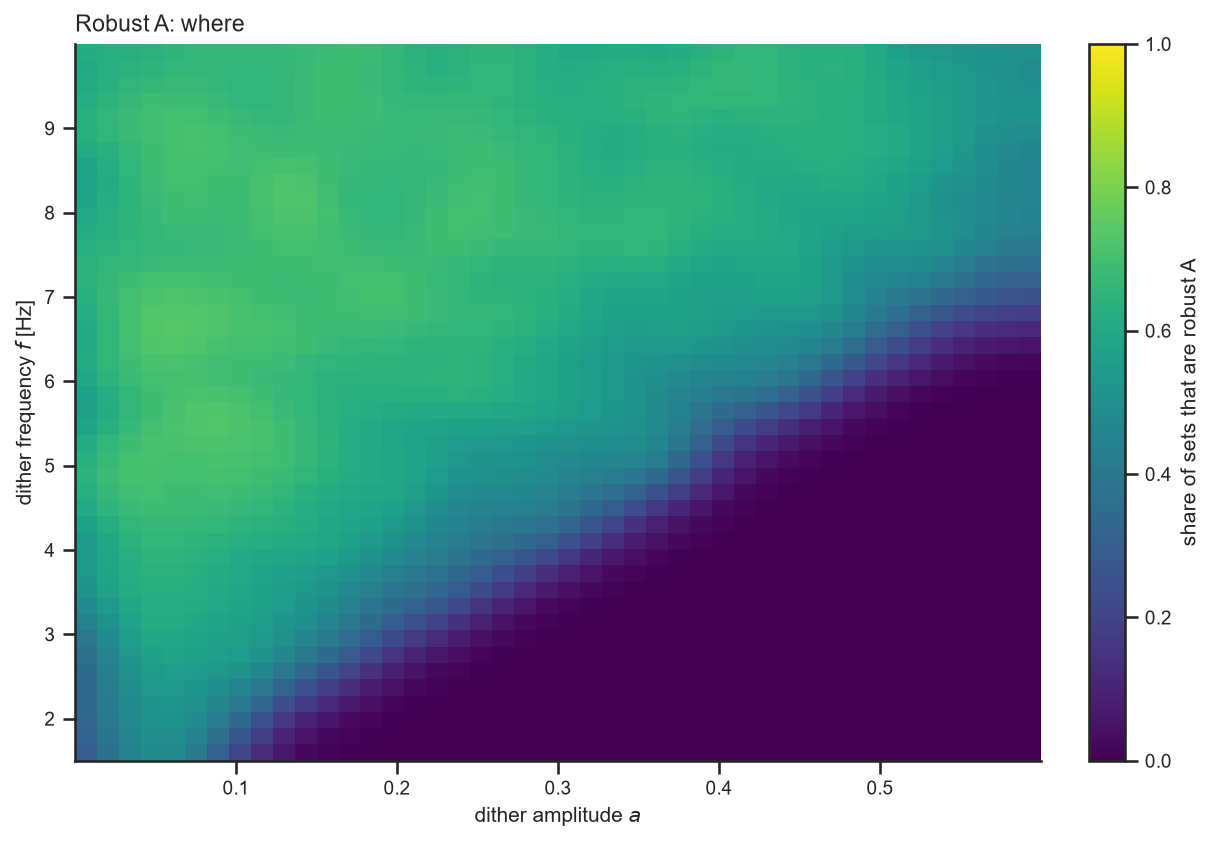

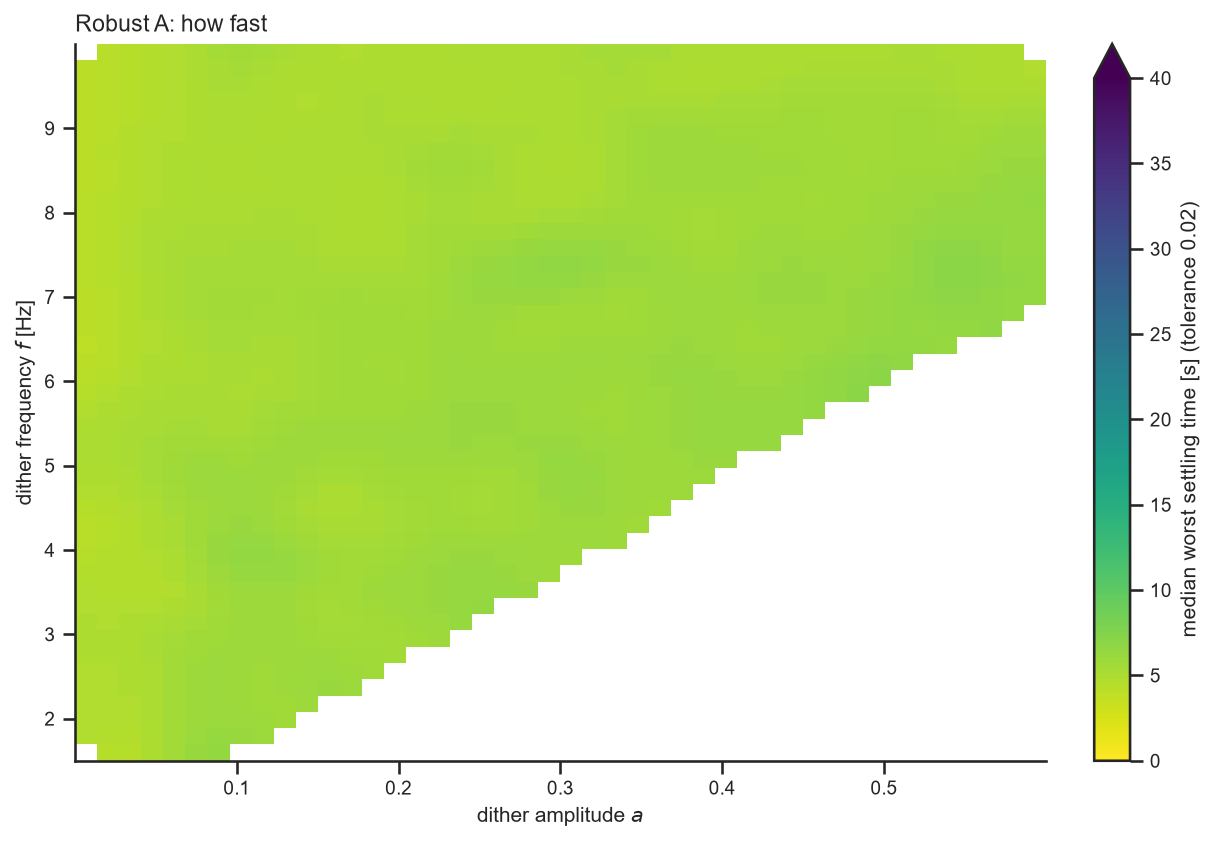

In [9]:
for x, x_label in views:
    x_edges = np.linspace(sets[x].min(), sets[x].max(), N_BINS + 1)
    y_edges = np.linspace(sets['dither_frequency'].min(), sets['dither_frequency'].max(), N_BINS + 1)
    share = esc.binned_map(sets[x], sets['dither_frequency'], robust.astype(float), x_edges, y_edges)
    fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained', dpi=150)
    image = ax.pcolormesh(x_edges, y_edges, share.T, cmap='viridis', vmin=0, vmax=1)
    fig.colorbar(image, ax=ax, label='share of sets that are robust A')
    ax.set_xlabel(x_label)
    ax.set_ylabel(esc.LABELS['dither_frequency'])
    ax.set_title('Robust A: where')
    ax.grid(False)
    plt.show()

    time_map = esc.binned_map(sets.loc[fast, x], sets.loc[fast, 'dither_frequency'], sets.loc[fast, 'worst settling time'],
                              x_edges, y_edges, statistic='median')
    fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained', dpi=150)
    image = ax.pcolormesh(x_edges, y_edges, time_map.T, cmap='viridis_r', vmin=0, vmax=40)
    fig.colorbar(image, ax=ax, label=f'median worst settling time [s] (tolerance {TOLERANCE})', extend='max')
    ax.set_xlabel(x_label)
    ax.set_ylabel(esc.LABELS['dither_frequency'])
    ax.set_title('Robust A: how fast')
    ax.grid(False)
    plt.show()

## 6. Picking sets

Among the robust-A sets that settle on every plant, the useful ones are fast **and** have a small tracking error.
The figure shows the trade-off; the reference set $k = 1$, $a = 0.2$, $f = 6$ Hz (used in `OTO-ESC_fix.ipynb`) is
simulated here with the same settings and marked. The table lists the fastest sets with the tighter tolerance 0.01,
among those with a worst tracking error below 0.005.

16,596 robust-A sets settle within 0.02 on every plant; 15,066 of them also settle within 0.01 and have a worst tracking error below 0.005. The fastest (tolerance 0.01):
Reference set k = 1, a = 0.2, f = 6 Hz on the eight plants:


,optimizer_gain,dither_amplitude,dither_frequency,worst eta,mean eta,worst settling time (0.02),worst settling time (0.01),worst tracking error,worst plant
18686,0.2555,0.0517,8.4093,0.9562,0.9851,2.10,2.79,0.0015,0.4625 up 0.0015
29330,0.2737,0.0276,9.4532,0.9573,0.9854,2.09,2.79,0.0015,0.4625 up 0.0015
19825,0.2494,0.0627,7.9981,0.9558,0.9850,2.12,2.81,0.0015,0.4625 up 0.0015
38549,0.2571,0.0501,8.5667,0.9561,0.9851,2.16,2.85,0.0015,0.4625 up 0.0015
12371,0.2762,0.0267,9.9260,0.9568,0.9852,2.15,2.85,0.0016,0.4625 up 0.0015
17043,0.2628,0.0215,8.8050,0.9570,0.9853,2.15,2.86,0.0015,0.4625 up 0.0015
5987,0.2639,0.0613,9.0402,0.9559,0.9850,2.12,2.86,0.0016,0.4625 up 0.0015
17700,0.2638,0.0526,9.2393,0.9557,0.9849,2.13,2.86,0.0016,0.4625 up 0.0015
9104,0.2645,0.1918,9.0932,0.9498,0.9826,2.17,2.87,0.0016,0.4625 up 0.0015
2299,0.2676,0.0189,9.3203,0.9567,0.9852,2.15,2.87,0.0016,0.4625 up 0.0015


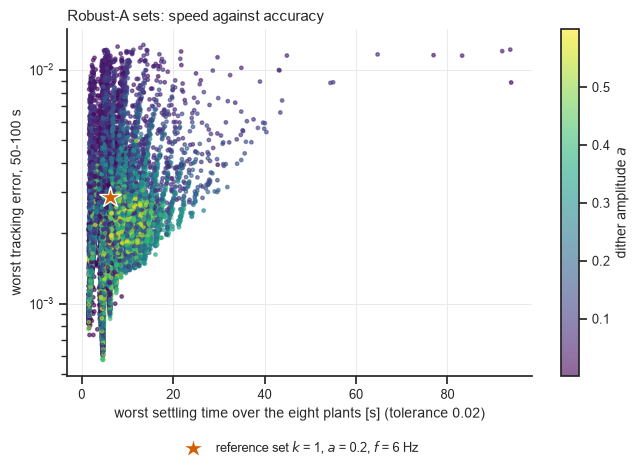

,eta,"tracking error, 50-100 s",settling time (0.01) [s],settling time (0.02) [s]
0.5 up 0.001,0.9932,0.0008,0.99,0.99
0.5 down 0.001,0.9922,0.0007,0.99,0.99
0.55 up 0.002,0.9981,0.0029,9.12,6.03
0.45 down 0.002,0.9969,0.0025,9.15,6.08
0.525,0.9884,0.0007,5.96,3.13
0.475,0.9830,0.0007,6.08,3.23
0.5375 down 0.0015,0.9765,0.0003,8.83,5.52
0.4625 up 0.0015,0.9655,0.0003,8.93,5.77


In [10]:
from IPython.display import display
import esc_sim as sim

plants = {name: (d['r_ideal_0'].iloc[0], d['lambda_r_ideal'].iloc[0]) for name, d in dfs.items()}


def evaluate(k, a, f):
    """One ESC set on the eight plants, with the settings of OTO_ESC_paired_Plant_fix.py."""
    names = list(plants)
    out = sim.simulate(k, a, f, r_ideal_0=np.array([plants[n][0] for n in names]),
                       lambda_r_ideal=np.array([plants[n][1] for n in names]), r_hat_0=0.5, steady_start=0.5,
                       track=True, settle_tolerances=(0.01, 0.02))
    fixed = np.array([dfs[n]['energy_const'].iloc[0] for n in names])
    ideal = np.array([dfs[n]['energy_ideal'].iloc[0] for n in names])
    return pd.DataFrame({'eta': (out['energy'] - fixed) / (ideal - fixed),
                         'tracking error, 50-100 s': out['tracking_error_late'],
                         'settling time (0.01) [s]': out['settling_time_0.01'],
                         'settling time (0.02) [s]': out['settling_time_0.02']}, index=names)


reference = evaluate(1, 0.2, 6)

candidates = sets[fast]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
points = ax.scatter(candidates['worst settling time'], candidates['worst tracking error'],
                    c=candidates['dither_amplitude'], cmap='viridis', s=6, alpha=0.6, rasterized=True)
ax.plot(reference[f'settling time ({TOLERANCE}) [s]'].max(), reference['tracking error, 50-100 s'].max(), marker='*',
        markersize=16, color=esc.COLORS['bad'], markeredgecolor='white', linestyle='none',
        label='reference set $k$ = 1, $a$ = 0.2, $f$ = 6 Hz')
fig.colorbar(points, ax=ax, label=esc.LABELS['dither_amplitude'])
ax.set_xlabel(f'worst settling time over the eight plants [s] (tolerance {TOLERANCE})')
ax.set_ylabel('worst tracking error, 50-100 s')
ax.set_yscale('log')
ax.set_title('Robust-A sets: speed against accuracy')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16))
plt.show()

# the tighter tolerance separates the sets better: with 0.02 many sets 'settle' after the first swing towards r_ideal
settling_tight = pd.DataFrame({name: d['settling_time_0.01'] for name, d in dfs.items()})
candidates = candidates.assign(**{'worst settling time (0.01)': settling_tight.max(axis=1).where(settling_tight.notna().all(axis=1))})
columns = esc.ESC_PARAMS + ['worst eta', 'mean eta', 'worst settling time', 'worst settling time (0.01)',
                            'worst tracking error', 'worst plant']
picked = (candidates[(candidates['worst tracking error'] < 0.005) & candidates['worst settling time (0.01)'].notna()]
          .sort_values('worst settling time (0.01)')[columns]
          .rename(columns={'worst settling time': f'worst settling time ({TOLERANCE})'}))
print(f'{len(candidates):,} robust-A sets settle within {TOLERANCE} on every plant; {len(picked):,} of them also settle '
      f'within 0.01 and have a worst tracking error below 0.005. The fastest (tolerance 0.01):')
display(picked.head(12).round(4))
print('Reference set k = 1, a = 0.2, f = 6 Hz on the eight plants:')
reference.round(4)

## 7. Mirror pairs with the steady start

With the steady start the initial densities of a plant and its twin are mirror images of each other. What remains
different is the direction of the first dither swing and, for the drifting plants, the shape of the drift
(see Section 8 of `OTO-Plant_fix.ipynb`). The table compares the two plants of each pair set by set.

In [11]:
rows = []
for first, twin in pairs:
    a, b = dfs[first], dfs[twin]
    rows.append({'pair': f'{first} / {twin}',
                 'same choose_ESC': (a['choose_ESC'] == b['choose_ESC']).mean(),
                 'same energy group': (a['energy_group'] == b['energy_group']).mean(),
                 'median |eta difference|': (a['eta'] - b['eta']).abs().median(),
                 '95 % of |eta differences| below': (a['eta'] - b['eta']).abs().quantile(0.95),
                 'correlation of settling times': a[f'settling_time_{TOLERANCE}'].corr(b[f'settling_time_{TOLERANCE}'])})
pd.DataFrame(rows).set_index('pair').round(3)

,same choose_ESC,same energy group,median |eta difference|,95 % of |eta differences| below,correlation of settling times
pair,,,,,
0.5 up 0.001 / 0.5 down 0.001,0.998,0.973,0.002,0.147,0.993
0.55 up 0.002 / 0.45 down 0.002,1.000,0.981,0.003,0.055,0.926
0.525 / 0.475,0.994,0.943,0.008,0.124,0.888
0.5375 down 0.0015 / 0.4625 up 0.0015,0.992,0.903,0.019,0.152,0.954


In [12]:
# numbers quoted in the notes below
above_one = (eta > 1).sum()
print(f'runs with eta > 1: {int(above_one.sum())} (at most {eta.max().max():.4f}); per plant: {above_one[above_one > 0].to_dict()}')
robust_settled = sets[(sets['tier'] == 'robust A') & sets['worst settling time'].notna()]
print('rank correlation of k and the worst settling time among robust-A sets: '
      f"{robust_settled['optimizer_gain'].corr(robust_settled['worst settling time'], method='spearman'):.2f}")
fastest = picked.head(int(0.02 * len(picked)))
print(f'fastest 2 % of the picked sets ({len(fastest)} sets): '
      f"k {fastest['optimizer_gain'].quantile(0.05):.2f}-{fastest['optimizer_gain'].quantile(0.95):.2f}, "
      f"f {fastest['dither_frequency'].quantile(0.05):.1f}-{fastest['dither_frequency'].quantile(0.95):.1f} Hz, "
      f"a {fastest['dither_amplitude'].quantile(0.05):.2f}-{fastest['dither_amplitude'].quantile(0.95):.2f}, "
      f"worst settling time (0.01) at most {fastest['worst settling time (0.01)'].max():.2f} s")

runs with eta > 1: 13 (at most 1.0066); per plant: {'0.475': 5, '0.5375 down 0.0015': 4, '0.4625 up 0.0015': 4}
rank correlation of k and the worst settling time among robust-A sets: 0.83
fastest 2 % of the picked sets (301 sets): k 0.15-0.26, f 4.5-9.8 Hz, a 0.02-0.40, worst settling time (0.01) at most 3.41 s


## Notes

**Results** (numbers printed above)

- With the steady start, ESC beats $r = 0.5$ for 92 to 100 % of the 40,000 sets on every plant, and 42 to 94 % of
  the sets reach $\eta \ge 0.9$ on a single plant. Judged by the worst plant, 41.8 % of the sets are robust A.
  The worst plant is almost always `0.4625 up 0.0015` (98 % of the sets): its ideal ratio crosses 0.5 during the run.
- **Mirror pairs now behave alike.** Plant and twin give the same `choose_ESC` for 99.2 to 100 % of the sets, and the
  settling times correlate with 0.89 to 0.99. In `OTO-Plant_fix.ipynb` (deuterium-rich start) the agreement was only
  79 to 97 %. This supports the conclusion of Section 8 there: most of the mirror differences came from the start.
  The margins of the static pair are identical (8.157 for 0.525 and 0.475).
- **The old convergence measure is misleading.** On the plants that start at $r_\mathrm{ideal} = 0.5$, 89 % of the
  sets count as converged at time 0. With large dither amplitudes ($a$ = 0.5 to 0.6) on `0.55 up 0.002`, only 74 %
  of the near-optimal sets count as converged, while 91 % settle within 0.02: the estimate $\hat r$ is not the
  ratio the plasma receives once the dither is clipped at 0 or 1.
- **Fast sets.** The fastest 2 % of the picked sets settle within 0.01 on every plant in at most 3.4 s. They have
  $k \approx 0.15$ to 0.26 with $f \approx 4.5$ to 10 Hz. Larger gains are slower ($k$ and the worst settling
  time have a rank correlation of 0.83 among the robust-A sets), because they overshoot. The fast region is a
  diagonal band in the $(k, f)$ map: a faster dither needs a larger gain, as in the averaged analysis.
- The reference set $k = 1$, $a = 0.2$, $f = 6$ Hz is robust A (worst $\eta$ 0.966 on `0.4625 up 0.0015`), settles
  within 0.01 in 9.2 s at the latest, and tracks to within 0.003 in the second half of the run.

**Limits and open points**

- The model has no measurement noise. That favours very small dither amplitudes (the fastest sets have
  $a$ down to 0.02), which would not work on a real, noisy signal. A noise model is needed before choosing $a$.
- The ratio the plasma receives is modelled as the requested ratio clipped to [0, 1]. The supervisor has described
  a different relation between the requested and the received ratio; `Tools/esc_sim.py` has an option
  `ratio_map` for it, which is not used yet.
- 13 runs score slightly above 1 (at most 1.0066): starting from the steady state at $r = 0.5$, following
  $r_\mathrm{ideal}(t)$ exactly is not the best possible path in the first seconds. The effect is below 0.05 energy units.
- The group limits ($\eta$ = 0.9, 0.5, 0.1), the tolerances (0.01, 0.02) and the start ratio 0.5 are proposals.
  A ratio error $\Delta$ costs about $4\Delta^2$ of the power in steady state, so 0.01 corresponds to 0.04 % and
  0.02 to 0.16 %.
- The sweep uses the Python simulator only; it has no MATLAB counterpart.